# LAB1 – Bài 2: Yêu cầu lập trình
**Sinh viên:** Đinh Văn Bình – **MSSV:** 6351071007

## Câu 4: Vẽ biểu đồ khảo sát sự liên quan giữa Cổng lên tàu (embarked), Loại vé (pclass) với khả năng sống sót (survived), phân biệt theo Giới tính (sex)

In [1]:
print('Họ tên: Đinh Văn Bình - MSSV: 6351071007')

Họ tên: Đinh Văn Bình - MSSV: 6351071007


### Bước 1. Import thư viện và đọc dữ liệu

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
%matplotlib inline
from matplotlib import pyplot as plt

with open('titanic.csv') as f:
    df = pd.read_csv(f, dtype={'age': np.float64, 'sibsp': np.int64, 'parch': np.int64})

print('Kích thước dữ liệu (dòng, cột):', df.shape)

Kích thước dữ liệu (dòng, cột): (1309, 14)


### Bước 2. Biểu đồ tỷ lệ sống sót theo Loại vé, mỗi Cổng lên tàu một hàng, phân biệt Giới tính
- Mỗi hàng là một cổng lên tàu: S (Southampton), C (Cherbourg), Q (Queenstown).
- Trục ngang: loại vé 1, 2, 3; trục dọc: tỷ lệ sống sót (0 → 1).
- Mỗi đường là một giới tính. Khai báo rõ `order` và `hue_order` để màu và chú thích (legend) khớp đúng giới tính.

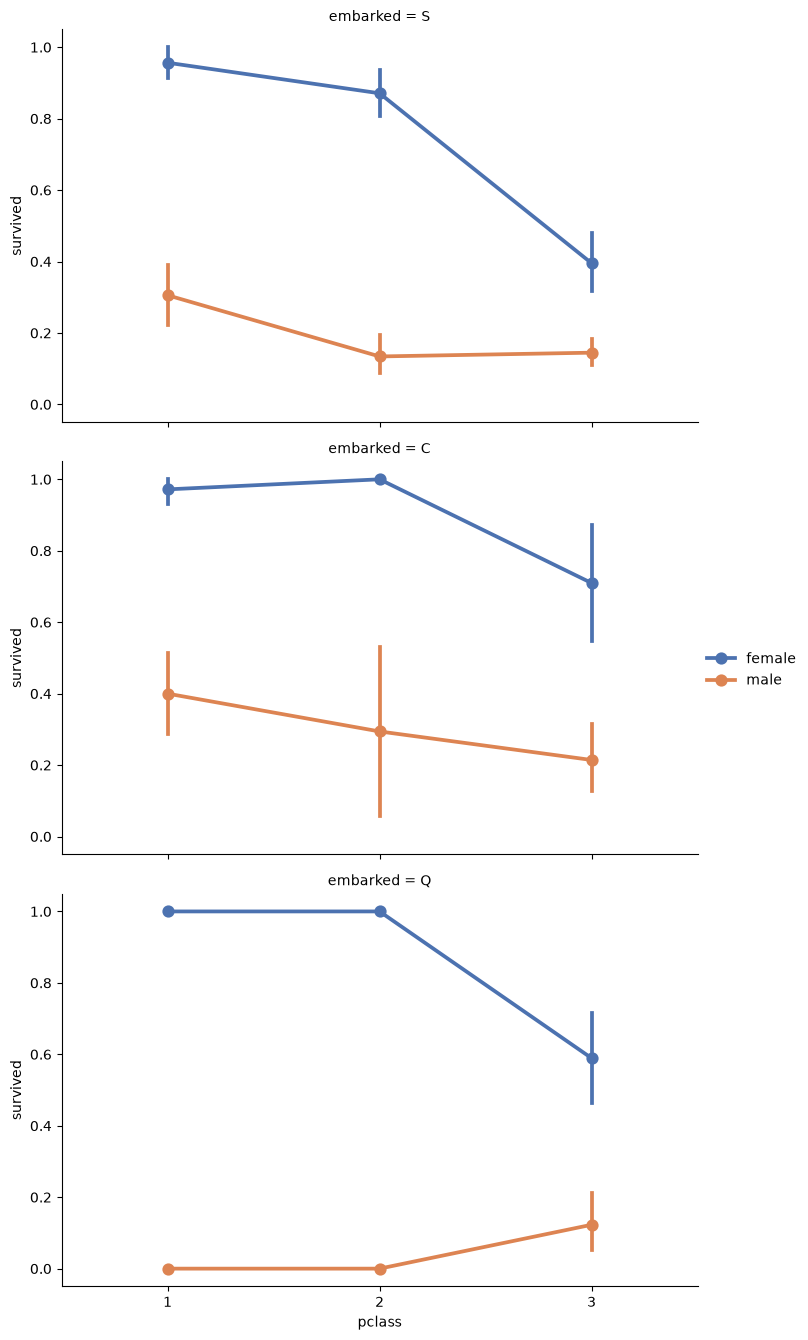

In [3]:
FacetGrid = sns.FacetGrid(df, row='embarked', row_order=['S', 'C', 'Q'], height=4.5, aspect=1.6)
FacetGrid.map(sns.pointplot, 'pclass', 'survived', 'sex', palette='deep',
              order=[1, 2, 3], hue_order=['female', 'male'])
FacetGrid.add_legend()

### Bước 3. Biểu đồ tỷ lệ sống sót theo Loại vé (pclass)

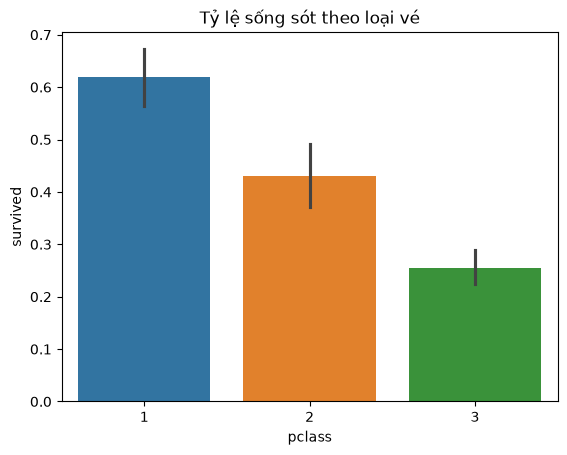

In [4]:
sns.barplot(x='pclass', y='survived', hue='pclass', data=df, palette='tab10', legend=False)
plt.title('Tỷ lệ sống sót theo loại vé')
plt.show()

### Bước 4. Phân bố tuổi theo Loại vé và khả năng sống sót
Mỗi hàng là một loại vé (1, 2, 3), cột trái: không sống sót (`survived = 0`), cột phải: sống sót (`survived = 1`).

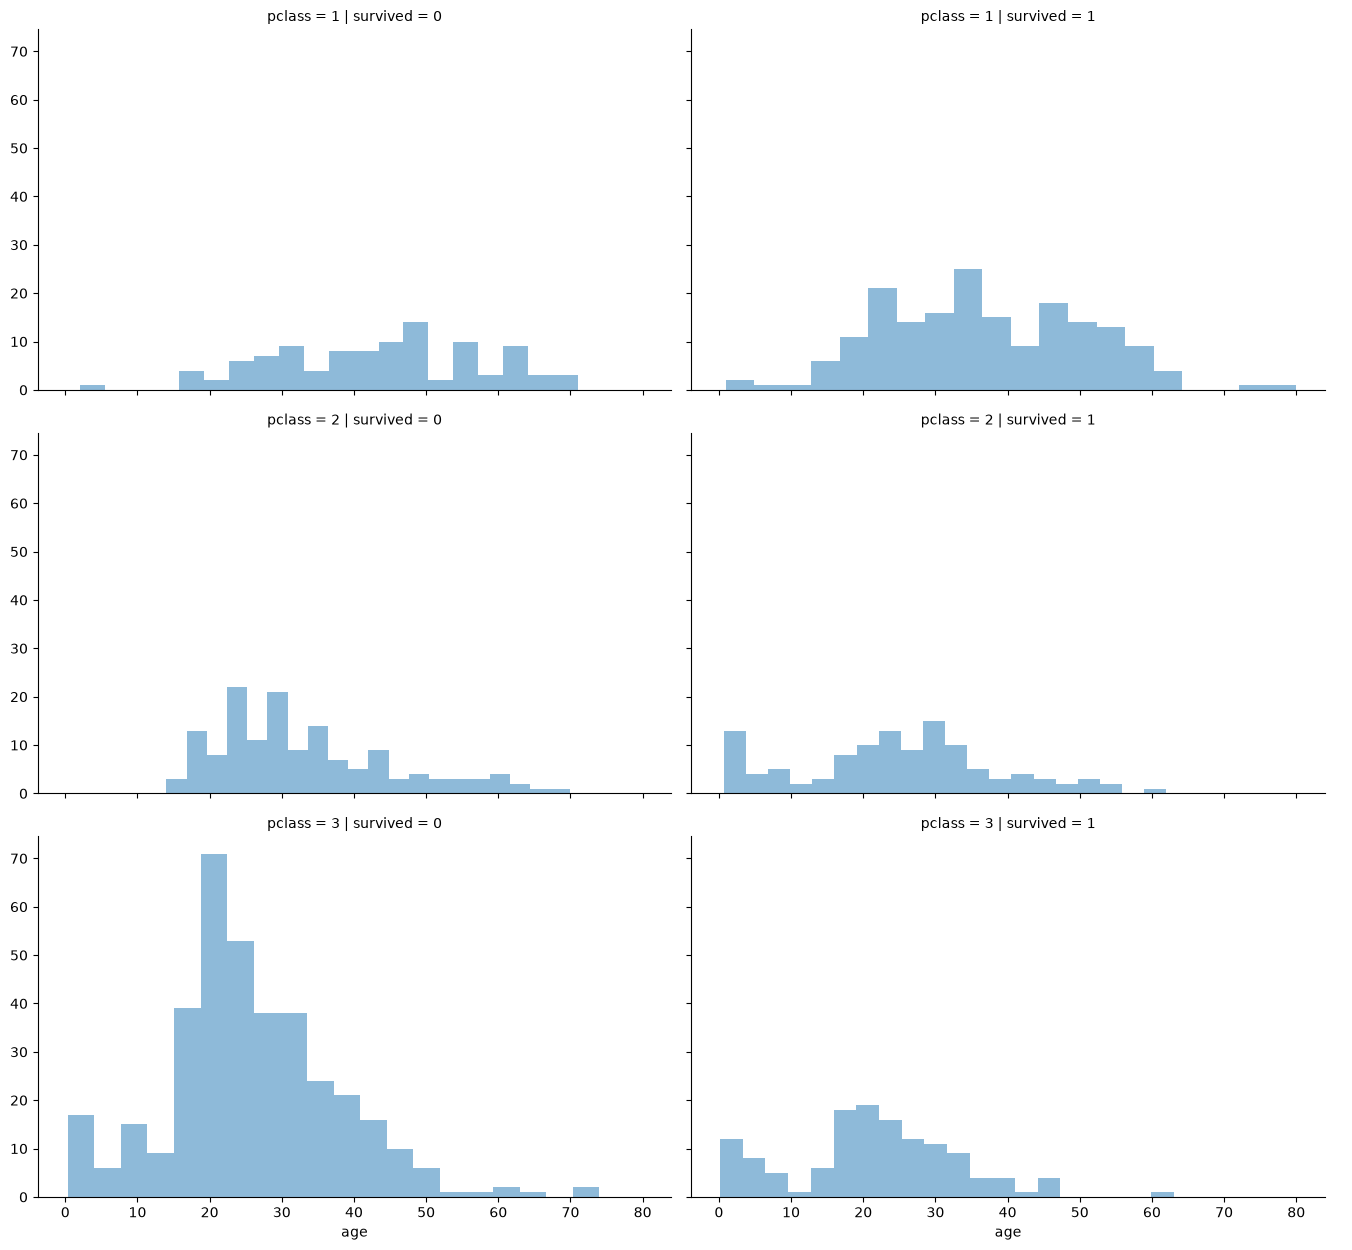

In [5]:
grid = sns.FacetGrid(df, col='survived', row='pclass', height=4.2, aspect=1.6)
grid.map(plt.hist, 'age', alpha=.5, bins=20)
grid.add_legend();

### Bước 5. Bảng số liệu minh họa cho nhận xét

In [6]:
print('Tỷ lệ sống sót (%) theo cổng lên tàu và giới tính:')
print((df.pivot_table(index='embarked', columns='sex', values='survived', aggfunc='mean') * 100).round(1))

print('\nTỷ lệ sống sót (%) theo loại vé:')
print((df.groupby('pclass')['survived'].mean() * 100).round(1))

print('\nTỷ lệ sống sót (%) theo cổng lên tàu, loại vé và giới tính:')
print((df.pivot_table(index=['embarked', 'pclass'], columns='sex', values='survived', aggfunc='mean') * 100).round(1))

print('\nSố hành khách theo cổng lên tàu và loại vé:')
print(pd.crosstab(df['embarked'], df['pclass']))

Tỷ lệ sống sót (%) theo cổng lên tàu và giới tính:
sex       female  male
embarked              
C           90.3  30.6
Q           61.7  11.1
S           68.0  17.0

Tỷ lệ sống sót (%) theo loại vé:
pclass
1    61.9
2    43.0
3    25.5
Name: survived, dtype: float64

Tỷ lệ sống sót (%) theo cổng lên tàu, loại vé và giới tính:
sex              female  male
embarked pclass              
C        1         97.2  40.0
         2        100.0  29.4
         3         71.0  21.4
Q        1        100.0   0.0
         2        100.0   0.0
         3         58.9  12.3
S        1         95.7  30.6
         2         87.1  13.4
         3         39.5  14.5

Số hành khách theo cổng lên tàu và loại vé:
pclass      1    2    3
embarked               
C         141   28  101
Q           3    7  113
S         177  242  495


### Nhận xét
**1. Cổng lên tàu (embarked) có liên quan đến khả năng sống sót và phụ thuộc vào giới tính**
- Ở cả 3 cổng, đường của **nữ (female) luôn nằm cao hơn hẳn nam (male)** → giới tính vẫn là yếu tố ảnh hưởng mạnh nhất.
- **Cổng C (Cherbourg)** có tỷ lệ sống sót cao nhất cho cả hai giới: nữ **90.3%**, nam **30.6%**.
- **Cổng Q (Queenstown)** có tỷ lệ sống sót thấp nhất: nữ 61.7%, nam chỉ **11.1%**; đặc biệt nam đi vé hạng 1 và 2 lên ở cổng Q không ai sống sót (tuy nhiên số người rất ít: hạng 1 chỉ 3 người, hạng 2 có 7 người).
- **Cổng S (Southampton)** đông khách nhất (914 người), tỷ lệ sống sót ở mức giữa: nữ 68.0%, nam 17.0%. Nữ đi vé hạng 3 lên ở cổng S có tỷ lệ sống sót thấp nhất trong các nhóm nữ (chỉ 39.5%).
- Nguyên nhân một phần là do **thành phần loại vé ở mỗi cổng khác nhau**: cổng C có nhiều khách hạng 1 (141/270), còn cổng Q gần như toàn khách hạng 3 (113/123).

**2. Loại vé (pclass) liên quan rõ rệt đến khả năng sống sót**
- Tỷ lệ sống sót giảm dần theo loại vé: hạng 1 **61.9%** → hạng 2 **43.0%** → hạng 3 **25.5%**. Tỷ lệ sống sót của loại vé 1 là cao nhất.
- Với nữ, vé hạng 1 và 2 có tỷ lệ sống sót gần như tuyệt đối (87–100%), nhưng giảm mạnh ở hạng 3 (39.5–71%).
- Với nam, vé hạng 1 có tỷ lệ sống sót cao nhất (30–40% ở cổng S và C), hạng 2 và 3 thấp hơn nhiều.
- Biểu đồ phân bố tuổi theo loại vé xác nhận nhận định trên: ở vé hạng 1, cột *sống sót* cao hơn cột *không sống sót*; ngược lại, những người đi **vé hạng 3 có tỷ lệ không sống sót lớn**, tập trung đông nhất ở độ tuổi khoảng 18–30.

**Kết luận:** `sex`, `pclass` và `embarked` đều có liên quan đến khả năng sống sót, trong đó **giới tính** ảnh hưởng mạnh nhất, tiếp theo là **loại vé**; ảnh hưởng của cổng lên tàu phần lớn đến từ việc mỗi cổng có tỷ lệ khách hạng sang khác nhau.